# Knowledge graph entity alignment

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/entity_alignment/entity_alignment.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/entity_alignment/entity_alignment.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/entity_alignment).

When data from two sources is combined, the same person, product, place, or work often
appears on both sides, described differently on each. Entity alignment decides which
record on one side describes the same entity as a record on the other. In a knowledge
graph, each entity has facts and links to other entities. Comparing every record with
every other is slow, so a cheap first step usually picks out pairs worth a closer
look, such as records with similar names. Each of those candidate pairs then needs a
decision, which we make here.

A wrong merge combines facts and links from different entities. Undoing it means working
out where each fact came from. A missed match leaves a duplicate. Pairs that need review
get a third outcome: send them to a curator, a person who decides by hand.

Jev makes this decision with a [`Score`](/primitives/score) question: you describe one
level per outcome, and the answer is a score along those levels. Here the levels are
leave unlinked, send for review, and recommend a merge (`assert sameAs`). On 450 album
pairs from two public music catalogs, we got 57 merge recommendations, 79 pairs for
review, and 314 left unlinked. The dataset records 48 of the 57 recommended merges as
matches.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/entity_alignment/entity_alignment-diagram-300f7aa42f.png" alt="Diagram" width="1176">

## Setup

Requires Python 3.10 or later. Choose a package manager to install the dependencies:

<Tabs sync={false}>
  <Tab title="pip">
    Create a virtual environment and add the dependencies:

    ```bash wrap
    python3 -m venv .venv
    .venv/bin/pip install matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
  <Tab title="uv">
    Initialize a project and add the dependencies:

    ```bash wrap
    uv init --bare
    uv add matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
</Tabs>

Set `TYPESAFE_API_KEY`. The code downloads the published answers into
`entity_alignment_cache.json`, so the run makes no requests; to run live, set
`DOWNLOAD_CACHE = False` and delete that file.

[pairs]: https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/entity_alignment/candidate_pairs.json
[license-data]: https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/entity_alignment/DATA_LICENSE.md

Numbers below came from `jev-1.14.0` on 2026-10-16.

In [ ]:
%pip install -q 'matplotlib' 'typesafe-sdk>=0.7.0' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Noul, Score, TypeSafeClient

matplotlib.use("Agg")  # headless render

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
MAX_WORKERS = 6  # small pool to stay under your organization's rate limits

client = TypeSafeClient(
    api_key=os.environ.get(
        "TYPESAFE_API_KEY", "cache-only"
    ),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)

In [ ]:
EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/entity_alignment"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("entity_alignment_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Load the candidate pairs

The pairs in [`candidate_pairs.json`][pairs] come from two public music catalogs,
Wikidata and MusicBrainz. Both release this data under CC0, which puts it in the public
domain. In each pair, `entity_a` is an album record from Wikidata and `entity_b` is a
release from MusicBrainz. Each entity has four fields: title, artist, year, and label.
[`DATA_LICENSE.md`][license-data] credits both sources.

Each pair also has `known_same_as`. It is true when a Wikidata editor linked the album to
the MusicBrainz release group that the release belongs to. Wikidata is a knowledge graph,
and that link is an entity alignment link. The 70 pairs marked true are called *known
matches* here. In the other 380, the Wikidata album links to a different MusicBrainz entry.
Nobody checked each pair by hand.

The text is left exactly as the catalogs publish it, with no cleanup: mixed casing and
alphabet systems, straight and curly apostrophes, and placeholders such as `[no label]`.
A missing value is `-`.

We send one request per pair, so the number of requests depends on the number of
candidate pairs, not the size of either catalog.

In [ ]:
DATA = Path("candidate_pairs.json")
DATA_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/entity_alignment/candidate_pairs.json"
)
if not DATA.exists():
    urllib.request.urlretrieve(DATA_URL, DATA)

PAIRS = json.loads(DATA.read_text(encoding="utf-8"))
BY_ID = {pair["id"]: pair for pair in PAIRS}

print(f"{len(PAIRS)} candidate pairs. The first one, as the model will see it:")
print(json.dumps({k: PAIRS[0][k] for k in ("entity_a", "entity_b")}, indent=2))

450 candidate pairs. The first one, as the model will see it:
{
  "entity_a": {
    "title": "My Refuge",
    "artist": "Alessandra Samadello",
    "year": "2003",
    "label": "-"
  },
  "entity_b": {
    "title": "My Refuge",
    "artist": "Kent Henry",
    "year": "1989",
    "label": "Hosanna! Music"
  }
}


## Ask one Score question and three Noul questions per candidate pair

The decision is a `Score` question because a `Score` attaches a written description to
each outcome in `LEVELS`, including the uncertain middle one, and keeps the three
outcomes in order. A `Noul` question could reach the middle outcome only indirectly, by
thresholding its output. A `Choice` question would lose the order of the three outcomes.

Put both entities into one state, as `entity_a` and `entity_b`, so each question is about
the pair. All four questions go in one request.
Title, artist, and label each get a `Noul` question to indicate where the records
disagree.

We round the score to the nearest level in `route()`. Write the level
descriptions before looking at the scores; the cut points follow from rounding rather
than being fitted to this dataset.

The middle level's wording decides which pairs reach a curator instead of being merged or
left unlinked, so it names the cases that need one: a reissue, a compilation, a special or
live edition, or a title that could refer to either album.

The merge recommendation is called `assert sameAs`: a recommendation to record that the
two entities are the same thing. That label is all `route()` returns; applying it to a
graph is a separate step.

There is no `Noul` question for the year, but the year is in the state.
For a year check, compare the two years in code and allow for a missing `-`.

The label question needs a rule, because catalogs disagree about which company to name.
We count a shortened name or a regional branch as the same label (*Columbia Records* and
*Columbia*, *EMI* and *EMI Music Brasil*). An imprint is a brand name a record company
releases under. We count an imprint and its parent company as different labels (*RCA
Victor* and *BMG*), because sharing a parent company does not establish that two albums
are the same.

To use this on another kind of data, swap in your own pairs and rewrite `QUESTIONS` and
`LEVELS`. The only other code that knows about albums is `show()`, which prints a pair
and names its fields.

In [ ]:
LEVELS = [
    "They describe two different albums.",
    "They describe closely related albums that may or may not be the same one: "
    "a reissue, a compilation, a special or live edition, or a title that could "
    "plausibly refer to either.",
    "They describe one and the same album.",
]
OUTCOME = {0: "leave unlinked", 1: "curator queue", 2: "assert sameAs"}

QUESTIONS = {
    "link_state": Score(
        instructions="How do the two entity descriptions relate as albums?",
        criteria=LEVELS,
    ),
    "same_title": Noul(
        instructions="Do the two entities give the same album title? Differences in "
        "casing, punctuation, or writing system (a title and its romanisation) do not "
        "make two titles different.",
    ),
    "same_artist": Noul(
        instructions="Do the two entities credit the same artist? A name written in "
        "another script or word order, or a credit that adds collaborators to the same "
        "lead artist, is the same artist.",
    ),
    "same_label": Noul(
        instructions="Do the two entities name the same record label? A shortened name "
        "or a regional branch of a label is the same label; an imprint and its parent "
        "company are different labels. A label of '-' or '[no label]' is not recorded.",
    ),
}


@json_cache
def score(state_json: str, questions_json: str, model: str) -> dict:
    """One request about one candidate pair -> the score plus the three noul answers."""
    questions = json.loads(questions_json)
    response = client.system_one(
        state=json.loads(state_json),
        questions=questions,
        model=model,
    )
    link = response.answers["link_state"]
    return {
        "score": link.score,
        "probabilities": link.probabilities,
        "confidence": link.confidence,
        "properties": {
            k: response.answers[k].noul for k in questions if k != "link_state"
        },
    }


def score_pair(pair: dict) -> dict:
    state = {"entity_a": pair["entity_a"], "entity_b": pair["entity_b"]}
    questions = {k: q.model_dump(mode="json", exclude_none=True) for k, q in QUESTIONS.items()}
    return score(json.dumps(state), json.dumps(questions), model=TYPESAFE_MODEL)


def route(score_value: float) -> str:
    """The whole decision rule: the nearest level names the outcome."""
    return OUTCOME[min(int(score_value + 0.5), len(LEVELS) - 1)]


def show(pair_id: str) -> None:
    pair = BY_ID[pair_id]
    result = score_pair(pair)
    print(
        f"{pair_id}  score {result['score']:.2f}  confidence {result['confidence']:.2f}"
        f"  ->  {route(result['score'])}"
    )
    for side in ("entity_a", "entity_b"):
        e = pair[side]
        print(
            f"    {e['title'][:40]:<42}{e['artist'][:26]:<28}{e['year']:<6}"
            f"{e['label'][:22]}"
        )
    nouls = result["properties"]
    print(
        f"    title {nouls['same_title']:.2f}   artist {nouls['same_artist']:.2f}   "
        f"label {nouls['same_label']:.2f}"
    )

In [ ]:
for pair_id in ("c115", "c133", "c190", "c159"):
    show(pair_id)
    print()

c115  score 1.76  confidence 0.64  ->  assert sameAs
    Lions                                     The Black Crowes            2001  V2 Records
    Lions                                     The Black Crowes            2001  V2 Records Japan
    title 0.99   artist 0.99   label 0.94

c133  score 0.14  confidence 0.80  ->  leave unlinked
    Freak of Nature                           Anastacia                   2001  Epic Records
    Freak of Nature                           Taylor Deupree              1996  Rancho Relaxo
    title 0.99   artist 0.01   label 0.01

c190  score 1.27  confidence 0.55  ->  curator queue
    Head Hunters                              Herbie Hancock              1973  Columbia Records
    Headhunters                               Herbie Hancock              2008  Columbia
    title 0.71   artist 0.99   label 0.96

c159  score 0.75  confidence 0.62  ->  curator queue
    McCartney III                             Paul McCartney              2020  Capitol Records
 

In `c115` both sides are the same album, with the same title and
artist. The label is *V2 Records* on one side and *V2 Records Japan* on the other. In
`c133` the two sides are different albums that share a title. The other two round to the
middle level for different reasons. In `c190` one side is a 2008 reissue of a 1973 album,
with the title spelled as one word. In `c159` one side is an album and the other is a
remix album made from it.

## Route every candidate pair

assert sameAs      57  (12.7%)
curator queue      79  (17.6%)
leave unlinked    314  (69.8%)


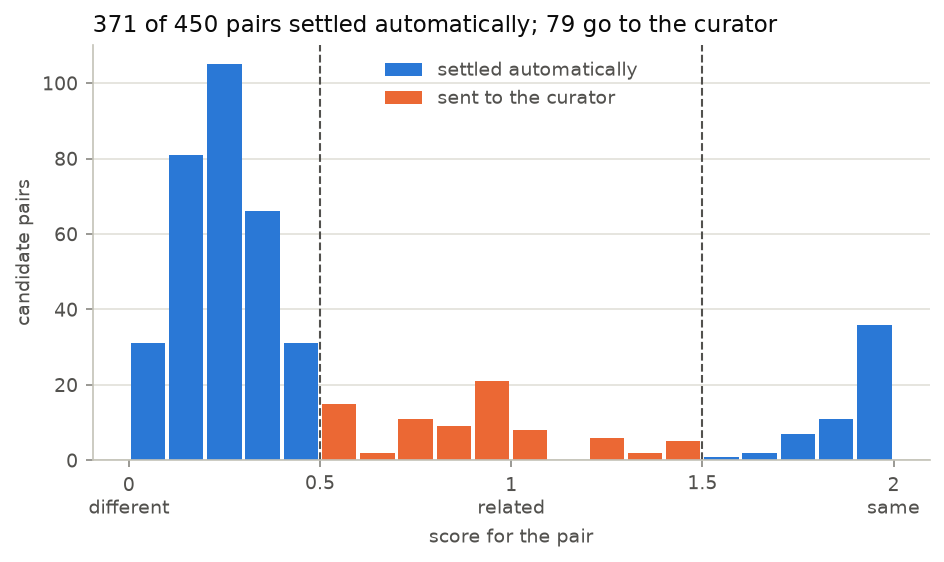

In [ ]:
# 450 candidate pairs, one request each; a live run takes about a minute.
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    scored = list(pool.map(score_pair, PAIRS))

scores = [result["score"] for result in scored]
by_outcome: dict[str, list[str]] = {name: [] for name in OUTCOME.values()}
for pair, s in zip(PAIRS, scores):
    by_outcome[route(s)].append(pair["id"])

CHART_PALETTES = {
    "light": {
        "surface": "#ffffff", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
        "grid": "#e1e0d9", "axis": "#c3c2b7", "blue": "#2a78d6", "orange": "#eb6834",
    },
    "dark": {
        "surface": "#0d0a0f", "ink": "#fafafa", "ink2": "#d4d4d8", "muted": "#a1a1aa",
        "grid": "#2e2e33", "axis": "#52525b", "blue": "#5b9be8", "orange": "#f08050",
    },
}


def draw_routing(p: dict) -> plt.Figure:
    BINS, TOP = 20, len(LEVELS) - 1
    counts = [0] * BINS
    for s in scores:
        counts[min(int(s / TOP * BINS), BINS - 1)] += 1
    centers = [(i + 0.5) / BINS * TOP for i in range(BINS)]
    queued = [c if route(x) == "curator queue" else 0 for c, x in zip(counts, centers)]
    settled = [c if route(x) != "curator queue" else 0 for c, x in zip(counts, centers)]

    fig, ax = plt.subplots(figsize=(7.2, 3.6), facecolor=p["surface"])
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["axis"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink2"], labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=p["grid"], linewidth=0.8)
    ax.bar(
        centers, settled, width=TOP / BINS * 0.9, color=p["blue"], label="settled automatically"
    )
    ax.bar(
        centers, queued, width=TOP / BINS * 0.9, color=p["orange"], label="sent to the curator"
    )
    for edge in (0.5, 1.5):
        ax.axvline(edge, color=p["ink2"], linewidth=1, linestyle="--")
    ax.set_xticks([0, 0.5, 1, 1.5, 2])
    ax.set_xticklabels(["0\ndifferent", "0.5", "1\nrelated", "1.5", "2\nsame"])
    ax.set_xlabel("score for the pair", color=p["ink2"], fontsize=9)
    ax.set_ylabel("candidate pairs", color=p["ink2"], fontsize=9)
    n_queued = len(by_outcome["curator queue"])
    ax.set_title(
        f"{len(PAIRS) - n_queued} of {len(PAIRS)} pairs settled automatically;"
        f" {n_queued} go to the curator",
        loc="left",
        color=p["ink"],
        fontsize=11,
    )
    ax.legend(frameon=False, labelcolor=p["ink2"], fontsize=9)
    return fig


# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_routing(CHART_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

for name in ("assert sameAs", "curator queue", "leave unlinked"):
    n = len(by_outcome[name])
    print(f"{name:<16}{n:>5}  ({n / len(PAIRS):>5.1%})")

The cut points are the two scores where `route()` changes its answer: 0.5 and 1.5. Most
pairs were routed without the curator: 314 scored below 0.5 and 57 scored at least 1.5,
which left 79 for the curator.

On this set, 257 of the 450 scores are between 0.1 and 0.4. Two different albums can
share a title, and a label name is weak evidence on its own, so the model gives the
middle level some probability even when a pair looks different. Routing depends only on
which side of a cut point the score falls: a pair at 0.4 is left unlinked, the same as a
pair at 0.

The three Noul answers help a curator inspect a pair, but only the Score decides its
route. Here are two pairs from the curator queue:

| Pair (Wikidata / MusicBrainz title) | Score | Same title | Same artist | Same label |
| :--- | ---: | ---: | ---: | ---: |
| `c190` *Head Hunters* / *Headhunters* | 1.27 | 0.71 | 0.99 | 0.96 |
| `c159` *McCartney III* / *McCartney III Imagined* | 0.75 | 0.02 | 0.98 | 0.99 |

In `c190` the artist and label agree and the title nearly does, and the 35 years between
the two releases point to a reissue. In `c159` everything agrees except the title, which
suggests a related album rather than the same one.

## Compare with the catalogs' own answer

Nothing above used `known_same_as`. We count it for each outcome to compare the routing
with what the catalogs recorded.

In [ ]:
print(f"{'':<16}{'known match':>13}{'known non-match':>17}")
for name in ("assert sameAs", "curator queue", "leave unlinked"):
    known = sum(BY_ID[pair_id]["known_same_as"] for pair_id in by_outcome[name])
    print(f"{name:<16}{known:>13}{len(by_outcome[name]) - known:>17}")

                  known match  known non-match
assert sameAs              48                9
curator queue              19               60
leave unlinked              3              311


The "known non-match" column counts the pairs where `known_same_as` is false. Of the 57
merges, 48 are known matches. Of the 314 pairs left unlinked, 311 are known non-matches.
The curator queue has 19 known matches and 60 known non-matches. The `known_same_as`
flag is not a checked answer, so this agreement is not a verified accuracy figure.

Some of the disagreements are mistakes in the catalogs. We looked up two of them in
MusicBrainz. In `c088`, both titles read *Um Novo Coração*, but the artists are Jozyanne
and Maíra. MusicBrainz has a separate entry for Jozyanne's album, and the Wikidata item
links to Maíra's instead, so `known_same_as` is true for two different albums. The model
left the pair unlinked. In `c415`, both sides are *Tonight: In Person* by The Limeliters,
from 1961 on RCA Victor. MusicBrainz lists the album twice and Wikidata links to the other
entry, so `known_same_as` is false. The model merged the pair. Six of the nine merged known
non-matches have the same title, artist, and year once case, punctuation, and accents are
ignored.

The model gets some pairs wrong too. It left two other known matches unlinked,
including `c444`, where one side credits *Justin Lo* and the other *側田*, the same singer's
Chinese name. Its `same_artist` answer is 0.03, and the pair scored 0.44, just under the
lower cut point.

In [ ]:
for pair_id in ("c088", "c415"):
    show(pair_id)
    print()

c088  score 0.43  confidence 0.35  ->  leave unlinked
    Um Novo Coração                           Jozyanne                    2001  MK Music
    Um novo coração                           Maíra                       2001  Paradoxx Music
    title 0.97   artist 0.01   label 0.01

c415  score 1.97  confidence 0.97  ->  assert sameAs
    Tonight: In Person                        The Limeliters              1961  RCA Victor
    Tonight, In Person                        The Limeliters              1961  RCA Victor
    title 0.86   artist 0.99   label 0.99


## Open it in the playground

The link below opens `c190` in the playground, with all four questions. The pair scored
1.27 and went to the curator. It's Herbie Hancock's *Head Hunters* from 1973 and the 2008
reissue *Headhunters*: the same artist, and the same label written two ways. The
playground runs `jev-latest`, so its score can differ from the 1.27 here.

In [ ]:
playground_link = make_playground_link(
    {
        "entity_a": BY_ID["c190"]["entity_a"],
        "entity_b": BY_ID["c190"]["entity_b"],
    },
    QUESTIONS,
)
display(
    Markdown(
        f"🔗 [Open this pair + questions in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open this pair + questions in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiMigJYoCeA+gIakEkiUoA2CT+pAEgvTD5eMVAgBOAZ1IAaHiHrjKklNz4SARhQTD6SKNADWs+dQHi1IAIwBOAOwBmE6Xb0NCdpYDCEdvC30+ABKCAbiYNIgAL5ypORUdBrcLGyclvyCABaiKBKRsQpKFCrpmtq6+kbOIGaKlgBMAAyNABzVru6eePI+fnABpFFRIHIgAA7iEHBjKJIY2N1ELhRIhrQq9LnJpDRjXN2kkmH7BSsq4jBQlBBIkQR8EADu+JD4KJk6KI8Q+PE0LwgjuIKDMKDdJPhxB5Njp6BD6OwNPBJAB+apQYG5YGMboAbVIaA+1ABQIo7je3xeFAAZtSJOR8AikXBJAA6aqEhDEsCAjFknRQdgQSQeYlQ1y5IRM5FvTKbfBwejEiDiBVK-BICAofDk946ST0RD4G4IAiBKHFSQwBByQIGaYUCVgpC2-CSPZQCgI42q9gUABuOgQYCozrkKsZbyonFl8oMMHYQjGrhgkjJ7DFCDpqpQPwQVA+4nZI3knO5vOB5JNjKQQj1bsNsMR8GLAF0YvIDYhaKl9swdtQ9pZNQnqmcUBcrs67vIACI-etfPOoUOA-AAcwDnw+DaN0rgUY4CBR+FnNOzyCga5W+CgcJW67kY1EVxgmzDPvwj0xD7d1BUCAHgAFIEvY1kIVAQpMipIMU743AAlC8PyatqiqGJ8lK9hCIa0vSqDFh2hyNgwRQlN0KSDn28gjl0py3BOlzXLcljzrKmHLmw2gQhiwZUOxu6wmRKAngAghqjZfpiuRIPgN56FqhZunyMyft84Q+jy4jhqqdpQiG2rvPKggRLevgdCqmwqhCuYCV2OicIIjLCXIxR2ZJijKCghEFPZtAdB42ysFRw4QKOJakOOk7MTOpBsYulJ-NxElGvW9mQqEKpCAF7BiW6mQqjJwYpToEbmggm43N6GjiHoUCZMa1KRjlck2Tu6U5QA3DWcnTMCqDgXJsz4GMigMvao1IMSY1UnhUIDTlbL4OJLUQE1ADkAC062futuKavgOWtjtbmoRlYQ8mAhHDKM9BjBQABqeTOos-pWNEQA)